# Imports and Setup

In [1]:
%load_ext autoreload

import logging
logging.basicConfig(level=logging.INFO, format='%(asctime)s - %(levelname)s - %(message)s') # NOTSET, DEBUG, INFO, WARN, ERROR, CRITICAL

import os
import numpy as np

import jax
import jax.numpy as jnp
from jax import vmap, jit, grad, jacfwd

# Optional: higher numeric accuracy (do this before heavy JAX use)
# try:
#     from jax import config as jax_config
#     jax_config.update("jax_enable_x64", True)
# except Exception:
#     pass

import skewerjax as sjx
from skewerjax.constants.physical_constants import phys

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
plt.style.use('tableau-colorblind10')
font, rcnew = sjx.config.setup_matplotlib.matplotlib_default_config()
plt.rc('font', **font)
plt.rcParams.update(rcnew)
%matplotlib widget

INFO:2026-01-11 10:58:38,072:jax._src.xla_bridge:752: Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-01-11 10:58:38,072 - INFO - Unable to initialize backend 'tpu': INTERNAL: Failed to open libtpu.so: libtpu.so: cannot open shared object file: No such file or directory
2026-01-11 10:58:38,274 - INFO - SkewerBundle class definition complete


# Fields

In [2]:
from skewerjax.skewers.skewers import SkewerBundle
from skewerjax.cosmology.cosmology import Cosmology

from skewerjax.fields.fields import ScalarField, VectorField, Fields
import skewerjax.fields.toy_model_samplers as toy_samplers

In [3]:
L_box = 1000.0 # UNITS: [Mpc]

fields = Fields({
    "HI": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min=1e0, T0_max=1e6, L_box=L_box)),       # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(v0_min=-300.0, v0_max=300.0, L_box=L_box)),        # UNITS: [km/s]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                                  # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0)),                                # UNITS: [GHz]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_min=1e0, n0_max=1e6, L_box=L_box)), # UNITS: [cm^-3]
    },
    "SiIII": {
        "temperature": ScalarField(toy_samplers.temperature_sampler(T0_min=1e0, T0_max=1e6, L_box=L_box)),       # UNITS: [K]
        "velocity": VectorField(toy_samplers.velocity_sampler(v0_min=-300.0, v0_max=300.0, L_box=L_box)),        # UNITS: [km/s]
        "turbulence": ScalarField(toy_samplers.turbulence_sampler(b_turb=0.0)),                                  # UNITS: [km/s]
        "collisional": ScalarField(toy_samplers.collisional_sampler(A_coll=0.0)),                                # UNITS: [GHz]
        "number_density": ScalarField(toy_samplers.number_density_sampler(n0_min=1e0, n0_max=1e6, L_box=L_box)), # UNITS: [cm^-3]
    }
})

In [4]:
import skewerjax.utils.aux as aux

### Create skewer bundles

In [5]:
N_sk = 7
N_ppsk = 5
N_grid = 64

In [6]:
# Create SkewerBundles
_points_1        = aux.make_plane_points(L_box, 'y', L_box/2, N_sk, N_ppsk)
skewer_bundle_1 = SkewerBundle(
    spatial_points=_points_1,
    a0=1.0,                                                      # scale factor at which ICs are defined, default: 1.0
    x0=0.0,                                                      # comoving distance at which ICs are defined, default: 0.0, UNITS: [Mpc]
    ICs_defined_at_index=-1,                                     # indices along the skewer where ICs are defined, (-1 means last point, 0 means first point), default: -1
    ICs_at_emission_or_absorption="absorption",                  # whether the ICs are defined at emission or absorption, default: 'absorption'
    los_directions=None,                                         # Let SkewerBundle compute los_directions automatically
    manual_scale_factors=jnp.ones_like(_points_1[None, ..., 0]), # if provided, must have shape (N_cosmologies, N_skewers, N_points_per_skewer)
    cosmologies=None                                             # when the manual scale factors are not provided, cosmologies must be defined
)

_points_T_imshow = aux.make_plane_points(L_box, 'y', L_box/2, N_grid, N_grid)
skewer_bundle_T_imshow = SkewerBundle(
    spatial_points=_points_T_imshow,
    manual_scale_factors=jnp.ones_like(_points_T_imshow[None, ..., 0])
)

_points_2        = aux.make_plane_points(L_box, 'x', L_box/2, N_sk, N_ppsk)
skewer_bundle_2 = SkewerBundle(
    spatial_points=_points_2,
    manual_scale_factors=jnp.ones_like(_points_2[None, ..., 0])
)

_points_n_imshow = aux.make_plane_points(L_box, 'x', L_box/2, N_grid, N_grid)
skewer_bundle_n_imshow = SkewerBundle(
    spatial_points=_points_n_imshow,
    manual_scale_factors=jnp.ones_like(_points_n_imshow[None, ..., 0])
)

2026-01-11 10:58:39,075 - INFO - Initializing SkewerBundle with 7 skewers, 5 points per skewer
2026-01-11 10:58:39,161 - INFO - Broadcasting scalar ICs_defined_at_index=-1 to all 7 skewers
2026-01-11 10:58:39,183 - INFO - All skewers set to absorption mode
2026-01-11 10:58:39,256 - INFO - Computing los_directions automatically from spatial coordinate differences
2026-01-11 10:58:39,539 - INFO - Computing comoving distances along skewer direction
2026-01-11 10:58:39,706 - INFO - Using provided scale factors (bypassing auto-calculation)
2026-01-11 10:58:39,707 - INFO - Storing quadri-vectors
2026-01-11 10:58:39,749 - INFO - SkewerBundle initialization complete
2026-01-11 10:58:39,886 - INFO - Initializing SkewerBundle with 64 skewers, 64 points per skewer
2026-01-11 10:58:39,905 - INFO - Broadcasting scalar ICs_defined_at_index=-1 to all 64 skewers
2026-01-11 10:58:39,920 - INFO - All skewers set to absorption mode
2026-01-11 10:58:39,988 - INFO - Computing los_directions automatically f

In [7]:
ii_cosmology = 0 # Select cosmology index, quadri_vectors shape: (N_cosmologies, N_skewers, N_points_per_skewer, 4), but here we have only one cosmology

quadri_vectors_1 = skewer_bundle_1.quadri_vectors[ii_cosmology]
LoS_directions_1 = skewer_bundle_1.los_directions
sampled_fields_1 = fields.sample(quadri_vectors_1, LoS_directions_1)

quadri_vectors_T_imshow = skewer_bundle_T_imshow.quadri_vectors[ii_cosmology]
T_imshow = fields.temperature(quadri_vectors_T_imshow)

quadri_vectors_2 = skewer_bundle_2.quadri_vectors[ii_cosmology]
LoS_directions_2 = skewer_bundle_2.los_directions
sampled_fields_2 = fields.sample(quadri_vectors_2, LoS_directions_2)

quadri_vectors_n_imshow = skewer_bundle_n_imshow.quadri_vectors[ii_cosmology]
n_imshow = fields.number_density(quadri_vectors_n_imshow)

In [8]:
marker_scatter_1 = "o"
marker_scatter_2 = "s"

key_species = "HI"
i_species = 0

/home/dlopez/tmp/pip-tmp/ipykernel_373006/2126514533.py:182: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout(rect=[0, 0, 1, 0.95])
/home/dlopez/.miniconda3/envs/skewerjax/lib/python3.11/site-packages/matplotlib/quiver.py:695: RuntimeWarning: divide by zero encountered in scalar divide
  length = a * (widthu_per_lenu / (self.scale * self.width))
/home/dlopez/.miniconda3/envs/skewerjax/lib/python3.11/site-packages/matplotlib/quiver.py:695: RuntimeWarning: invalid value encountered in multiply
  length = a * (widthu_per_lenu / (self.scale * self.width))


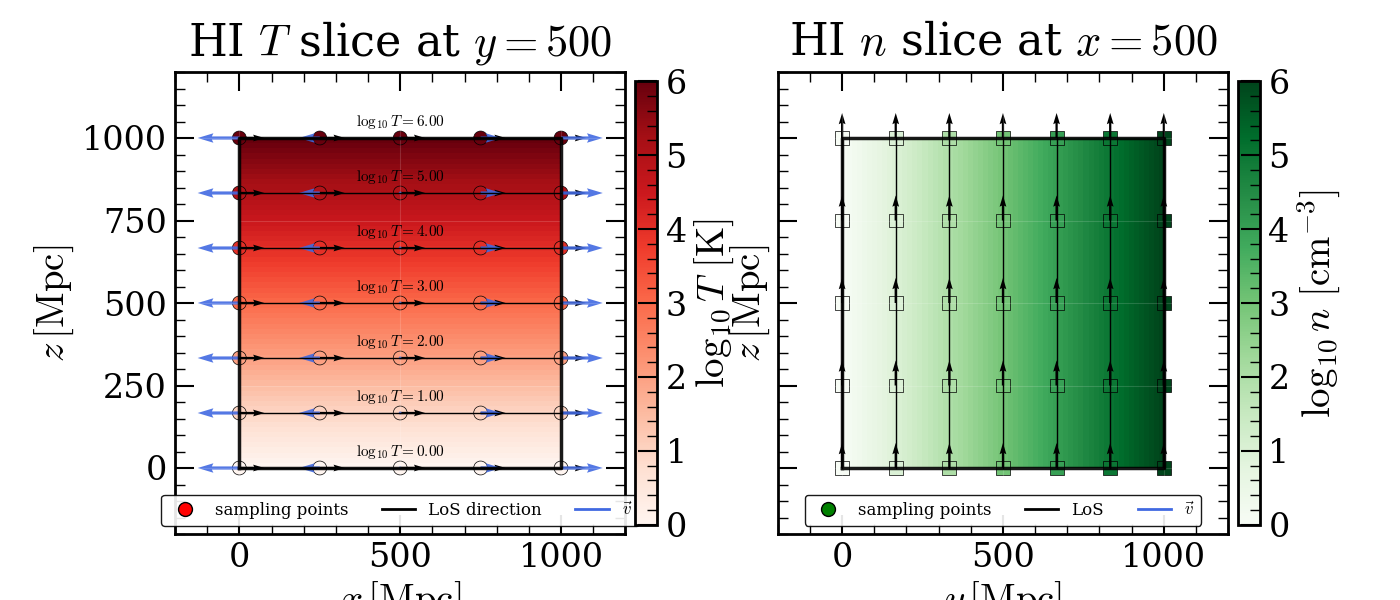

In [9]:
fig, (axT, axN) = plt.subplots(
    1, 2, figsize=(14, 6), sharey=True,
    gridspec_kw=dict(wspace=0.25)
)

# ============================================================
# LEFT PANEL: Temperature slice (x–z, y = L_box/2)
# ============================================================
# Background: log10 T
logT = np.log10(np.array(T_imshow[i_species]))     # (N_grid, N_grid)
x_min, x_max = float(quadri_vectors_T_imshow[..., 1].min()), float(quadri_vectors_T_imshow[..., 1].max())
z_min_T, z_max_T = float(quadri_vectors_T_imshow[..., -1].min()), float(quadri_vectors_T_imshow[..., -1].max())

norm_T = mpl.colors.Normalize(vmin=logT.min(), vmax=logT.max())
cmap_T = mpl.cm.Reds

im_T = axT.imshow(
    logT, origin="lower", extent=(x_min, x_max, z_min_T, z_max_T), aspect="auto", cmap=cmap_T, norm=norm_T,
)
cbar_T = fig.colorbar(im_T, ax=axT, pad=0.02, fraction=0.046)
cbar_T.set_label(r"$\log_{10} T\ \mathrm{[K]}$")

# Skewer points colored by log10 T
T_all = np.asarray(sampled_fields_1[key_species]["temperature"])   # (N_sk, N_ppsk)
log10_T_all = np.log10(T_all)
x1 = np.asarray(quadri_vectors_1[..., 1])  # (N_sk, N_ppsk)
z1 = np.asarray(quadri_vectors_1[..., -1]) # (N_sk, N_ppsk)

axT.scatter(
    x1.ravel(), z1.ravel(), c=log10_T_all.ravel(),
    cmap=cmap_T, norm=norm_T, marker=marker_scatter_1, s=100, alpha=1.0, edgecolor="k", linewidth=0.5,
)

# Skewer lines + LoS arrows
for i in range(quadri_vectors_1.shape[0]):
    axT.plot(
        quadri_vectors_1[i, ..., 1], quadri_vectors_1[i, ..., -1],
        color="k", linewidth=1.0, alpha=1.0,
    )
    axT.quiver(
        quadri_vectors_1[i, ..., 1], quadri_vectors_1[i, ..., -1],
        LoS_directions_1[i, :, 0].T, LoS_directions_1[i, :, 2].T,
        color="k", angles="xy", scale_units="xy", scale=None, width=0.005, alpha=1.0,
    )

# Gas velocities (xz components)
axT.quiver(
    quadri_vectors_1[..., 1], quadri_vectors_1[..., -1],
    sampled_fields_1[key_species]["velocity"][..., 0],
    sampled_fields_1[key_species]["velocity"][..., 2],
    color="royalblue", angles="xy", scale_units="xy", scale=None, width=0.007, alpha=0.9,
)

# Domain frame & limits
axT.plot(
    [x_min, x_max, x_max, x_min, x_min],
    [z_min_T, z_min_T, z_max_T, z_max_T, z_min_T],
    color="k",
    linewidth=2.5,
    alpha=0.9,
)
limit_padding = 200
axT.set_xlim(x_min - limit_padding, x_max + limit_padding)
axT.set_ylim(z_min_T - limit_padding, z_max_T + limit_padding)

# Labels, title, grid
axT.set_xlabel(r"$x\, [\mathrm{Mpc}]$")
axT.set_ylabel(r"$z\, [\mathrm{Mpc}]$")
axT.set_title(rf"{key_species} $T$ slice at $y={float(L_box/2):.3g}$", pad=12)
axT.grid(color="w", linewidth=0.8, alpha=0.15)

# Label each skewer with its (log10) temperature
T_sample = np.array(sampled_fields_1[key_species]["temperature"])  # (N_sk, N_ppsk)
dz_T = (z_max_T - z_min_T)
for i in range(quadri_vectors_1.shape[0]):
    z_i = float(quadri_vectors_1[i, 0, -1])
    x_center = float(quadri_vectors_1[i, ..., 1].mean())
    logT_i = np.log10(T_sample[i, 0])  # assume constant along skewer
    axT.text(
        x_center,
        z_i + 0.02 * dz_T,
        rf"$\log_{{10}} T = {logT_i:.2f}$",
        color="k", ha="center", va="bottom", fontsize=11,
        bbox=dict(boxstyle="round,pad=0.2", facecolor="k", alpha=0.0),
    )

# Legend for left panel
legend_handles_T = [
    Line2D([0], [0], marker="o", linestyle="none",
           markerfacecolor="red", markeredgecolor="k",
           markersize=10, label="sampling points"),
    Line2D([0], [0], color="k", lw=2, label="LoS direction"),
    Line2D([0], [0], color="royalblue", lw=2, label=r"$\vec{v}$"),
]
leg_T = axT.legend(
    handles=legend_handles_T, loc="lower center", frameon=True, fontsize=12, framealpha=0.9, ncols=3,
)
leg_T.get_frame().set_edgecolor("k")

# ============================================================
# RIGHT PANEL: Number-density slice (y–z, x = L_box/2)
# ============================================================
# Background: log10 n
logn = np.log10(np.array(n_imshow[i_species]))     # (N_grid, N_grid)
y_min, y_max = float(quadri_vectors_n_imshow[..., 2].min()), float(quadri_vectors_n_imshow[..., 2].max())
z_min_n, z_max_n = float(quadri_vectors_n_imshow[..., 3].min()), float(quadri_vectors_n_imshow[..., 3].max())

norm_n = mpl.colors.Normalize(vmin=logn.min(), vmax=logn.max())
cmap_n = mpl.cm.Greens

im_n = axN.imshow(
    logn.T, origin="lower", extent=(y_min, y_max, z_min_n, z_max_n), aspect="auto", cmap=cmap_n, norm=norm_n,
)
cbar_n = fig.colorbar(im_n, ax=axN, pad=0.02, fraction=0.046)
cbar_n.set_label(r"$\log_{10} n\ \mathrm{[cm^{-3}]}$")

# Skewer points colored by log10 n
n_all = np.asarray(sampled_fields_2[key_species]["number_density"])  # (N_sk, N_ppsk)
log10_n_all = np.log10(n_all)
y2 = np.asarray(quadri_vectors_2[..., 2])  # (N_sk, N_ppsk)
z2 = np.asarray(quadri_vectors_2[..., 3])  # (N_sk, N_ppsk)

axN.scatter(
    y2.ravel(), z2.ravel(), c=log10_n_all.ravel(),
    cmap=cmap_n, norm=norm_n, marker=marker_scatter_2, s=100,
    alpha=1.0, edgecolor="k", linewidth=0.5,
)

# Skewer lines + LoS arrows
for i in range(quadri_vectors_2.shape[0]):
    axN.plot(
        quadri_vectors_2[i, ..., 2], quadri_vectors_2[i, ..., 3],
        color="k", linewidth=1.0, alpha=1.0,
    )
    axN.quiver(
        quadri_vectors_2[i, ..., 2], quadri_vectors_2[i, ..., 3],
        LoS_directions_2[i, :, 1].T, LoS_directions_2[i, :, 2].T,
        color="k", angles="xy", scale_units="xy", scale=None, width=0.005, alpha=1.0,
    )

# Gas velocities (yz components)
axN.quiver(
    quadri_vectors_2[..., 2], quadri_vectors_2[..., 3],
    sampled_fields_2[key_species]["velocity"][..., 1],
    sampled_fields_2[key_species]["velocity"][..., 2],
    color="royalblue", angles="xy", scale_units="xy", scale=None, width=0.007, alpha=0.9,
)

# Domain frame & limits (use y,z extents here)
axN.plot(
    [y_min, y_max, y_max, y_min, y_min],
    [z_min_n, z_min_n, z_max_n, z_max_n, z_min_n],
    color="k", linewidth=2.5, alpha=0.9,
)
axN.set_xlim(y_min - limit_padding, y_max + limit_padding)
axN.set_ylim(z_min_n - limit_padding, z_max_n + limit_padding)

# Labels, title, grid
axN.set_xlabel(r"$y\, [\mathrm{Mpc}]$")
axN.set_ylabel(r"$z\, [\mathrm{Mpc}]$")
axN.set_title(rf"{key_species} $n$ slice at $x={float(L_box/2):.3g}$", pad=12)
axN.grid(color="w", linewidth=0.8, alpha=0.15)

# Legend for right panel
legend_handles_n = [
    Line2D([0], [0], marker="o", linestyle="none",
           markerfacecolor="green", markeredgecolor="k",
           markersize=10, label="sampling points"),
    Line2D([0], [0], color="k", lw=2, label="LoS"),
    Line2D([0], [0], color="royalblue", lw=2, label=r"$\vec{v}$"),
]
leg_n = axN.legend(
    handles=legend_handles_n,
    loc="lower center",
    frameon=True,
    fontsize=12,
    framealpha=0.9,
    ncols=3,
)
leg_n.get_frame().set_edgecolor("k")

plt.tight_layout(rect=[0, 0, 1, 0.95])
plt.show()

/home/dlopez/tmp/pip-tmp/ipykernel_373006/2315254652.py:265: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


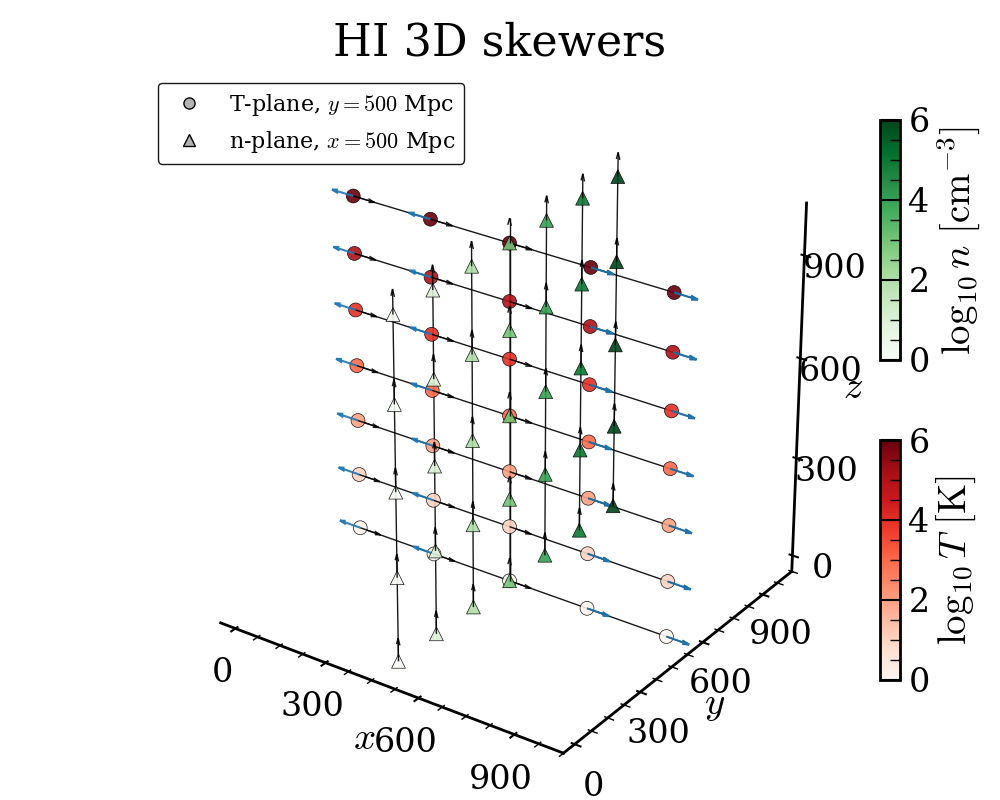

In [10]:
L = float(L_box)

# ----------------------
# Y-plane (temperature)
# ----------------------
# coordinates
x_y = np.asarray(quadri_vectors_1[..., 1])   # (N_sk, N_ppsk)
y_y = np.asarray(quadri_vectors_1[..., 2])   # constant y = y_plane
z_y = np.asarray(quadri_vectors_1[..., 3])   # (N_sk, N_ppsk)

y_plane = float(y_y[0, 0])

# sampled fields
T_y   = np.asarray(sampled_fields_1[key_species]["temperature"])   # (N_sk, N_ppsk)
vel_y = np.asarray(sampled_fields_1[key_species]["velocity"])      # (N_sk, N_ppsk, 3)
LoS_y = np.asarray(LoS_directions_1)                                          # (N_sk, N_ppsk, 3)

logT_y = np.log10(T_y)
norm_T = mpl.colors.Normalize(vmin=logT_y.min(), vmax=logT_y.max())
cmap_T = mpl.cm.Reds

# ----------------------
# X-plane (number density) – single plane at x = L_box/2
# ----------------------
x_x = np.asarray(quadri_vectors_2[..., 1])    # constant x = x_plane
y_x = np.asarray(quadri_vectors_2[..., 2])    # (N_sk, N_ppsk)
z_x = np.asarray(quadri_vectors_2[..., 3])    # (N_sk, N_ppsk)

x_plane = float(x_x[0, 0])

n_all = np.asarray(sampled_fields_2[key_species]["number_density"])  # (N_sk, N_ppsk)
vel_x = np.asarray(sampled_fields_2[key_species]["velocity"])        # (N_sk, N_ppsk, 3)
LoS_x = np.asarray(LoS_directions_2)                                            # (N_sk, N_ppsk, 3)

logn_all = np.log10(n_all)
norm_n = mpl.colors.Normalize(vmin=logn_all.min(), vmax=logn_all.max())
cmap_n = mpl.cm.Greens

# ---------------------------------------------------------
# 3D plot
# ---------------------------------------------------------
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")

# Some style choices (you probably already have these defined)
los_line_color  = "k"
vel_arrow_color = "tab:blue"

# =========================================================
# Y-plane: points + lines + arrows
# =========================================================
N_sk, N_ppsk = x_y.shape

# Flatten for scatter
x_y_f    = x_y.ravel()
y_y_f    = y_y.ravel()
z_y_f    = z_y.ravel()
logT_y_f = logT_y.ravel()
colors_y = cmap_T(norm_T(logT_y_f))

ax.scatter(
    x_y_f, y_y_f, z_y_f,
    c=colors_y,
    marker="o",
    s=100,
    alpha=0.9,
    edgecolor="k",
    linewidth=0.5,
)

# Join points along each skewer (fixed z index)
for i in range(N_sk):
    ax.plot(
        x_y[i, :], y_y[i, :], z_y[i, :],
        color=los_line_color,
        linewidth=1.0,
        alpha=0.9,
    )

# Subsample for arrows
N_sk_y, N_ppsk_y, _ = vel_y.shape
step_z_y = max(1, N_sk_y  // 5)
step_x_y = max(1, N_ppsk_y // 5)

Xq_y = x_y[::step_z_y, ::step_x_y]
Yq_y = y_y[::step_z_y, ::step_x_y]
Zq_y = z_y[::step_z_y, ::step_x_y]

U_LoS_y = LoS_y[::step_z_y, ::step_x_y, 0]
V_LoS_y = LoS_y[::step_z_y, ::step_x_y, 1]
W_LoS_y = LoS_y[::step_z_y, ::step_x_y, 2]

U_v_y = vel_y[::step_z_y, ::step_x_y, 0]
V_v_y = vel_y[::step_z_y, ::step_x_y, 1]
W_v_y = vel_y[::step_z_y, ::step_x_y, 2]

# LoS arrows (y-plane) – all black
ax.quiver(
    Xq_y, Yq_y, Zq_y,
    U_LoS_y, V_LoS_y, W_LoS_y,
    length=0.07 * L,
    normalize=True,
    color=los_line_color,
    linewidth=1.0,
    alpha=0.9,
)

# 3D velocity arrows (y-plane) – all same color
ax.quiver(
    Xq_y, Yq_y, Zq_y,
    U_v_y, V_v_y, W_v_y,
    length=0.07 * L,
    normalize=True,
    color=vel_arrow_color,
    linewidth=1.5,
    alpha=0.9,
)

# =========================================================
# X-plane: points + lines + arrows (using sampled_fields_2)
# =========================================================
# You can pick any marker; here just one marker type
x_plane_marker = "^"

ax.scatter(
    x_x.ravel(), y_x.ravel(), z_x.ravel(),
    c=cmap_n(norm_n(logn_all.ravel())),
    marker=x_plane_marker,
    s=100,
    alpha=0.9,
    edgecolor="k",
    linewidth=0.5,
)

# Join points along skewers (fixed "z index" – i.e., along y axis)
for i in range(N_sk):
    ax.plot(
        x_x[i, :], y_x[i, :], z_x[i, :],
        color=los_line_color,
        linewidth=1.0,
        alpha=0.9,
    )

# Subsample for arrows
N_sk_x, N_ppsk_x, _ = vel_x.shape
step_z_x = max(1, N_sk_x  // 5)
step_y_x = max(1, N_ppsk_x // 5)

Xq_x = x_x[::step_z_x, ::step_y_x]
Yq_x = y_x[::step_z_x, ::step_y_x]
Zq_x = z_x[::step_z_x, ::step_y_x]

U_LoS_x = LoS_x[::step_z_x, ::step_y_x, 0]
V_LoS_x = LoS_x[::step_z_x, ::step_y_x, 1]
W_LoS_x = LoS_x[::step_z_x, ::step_y_x, 2]

U_v_x = vel_x[::step_z_x, ::step_y_x, 0]
V_v_x = vel_x[::step_z_x, ::step_y_x, 1]
W_v_x = vel_x[::step_z_x, ::step_y_x, 2]

# LoS arrows (x-plane) – all black
ax.quiver(
    Xq_x, Yq_x, Zq_x,
    U_LoS_x, V_LoS_x, W_LoS_x,
    length=0.07 * L,
    normalize=True,
    color=los_line_color,
    linewidth=1.0,
    alpha=0.9,
)

# 3D velocity arrows (x-plane) – same color as y-plane
ax.quiver(
    Xq_x, Yq_x, Zq_x,
    U_v_x, V_v_x, W_v_x,
    length=0.07 * L,
    normalize=True,
    color=vel_arrow_color,
    linewidth=1.5,
    alpha=0.9,
)

# =========================================================
# Intersection line of x-plane and y-plane
# =========================================================
z_line = np.linspace(0.0, L, 100)
x_line = np.full_like(z_line, x_plane)
y_line = np.full_like(z_line, y_plane)
ax.plot(
    x_line, y_line, z_line,
    color="k",
    linewidth=1.5,
    alpha=0.5,
)

# =========================================================
# Colorbars for T and n (using precomputed logs)
# =========================================================
sm_T = mpl.cm.ScalarMappable(norm=norm_T, cmap=cmap_T)
sm_T.set_array([])
sm_n = mpl.cm.ScalarMappable(norm=norm_n, cmap=cmap_n)
sm_n.set_array([])

# Place them manually on the right
cax_T = fig.add_axes([0.88, 0.15, 0.02, 0.30])  # lower bar
cax_n = fig.add_axes([0.88, 0.55, 0.02, 0.30])  # upper bar

cbar_T = fig.colorbar(sm_T, cax=cax_T)
cbar_T.set_label(r"$\log_{10} T\ \mathrm{[K]}$")

cbar_n = fig.colorbar(sm_n, cax=cax_n)
cbar_n.set_label(r"$\log_{10} n\ \mathrm{[cm^{-3}]}$")

# =========================================================
# Axes, aspect, limits, ticks, legend
# =========================================================
ax.set_xlabel(r"$x$")
ax.set_ylabel(r"$y$")
ax.set_zlabel(r"$z$")
ax.set_title(rf"{key_species} 3D skewers", pad=12)

ax.grid(False)

pad = 0.05 * L
ax.set_xlim(-pad, L + pad)
ax.set_ylim(-pad, L + pad)
ax.set_zlim(-pad, L + pad)

ax.xaxis.set_major_locator(mpl.ticker.MaxNLocator(4))
ax.yaxis.set_major_locator(mpl.ticker.MaxNLocator(4))
ax.zaxis.set_major_locator(mpl.ticker.MaxNLocator(4))

# remove axis panes (background planes)
for axis in (ax.xaxis, ax.yaxis, ax.zaxis):
    try:
        axis.pane.set_visible(False)
    except AttributeError:
        pass

ax.set_box_aspect((L + 2*pad, L + 2*pad, L + 2*pad))
ax.view_init(elev=28, azim=-55)

legend_handles = [
    Line2D(
        [0], [0], marker="o", linestyle="none",
        markerfacecolor="0.7", markeredgecolor="k",
        markersize=8, label=rf"T-plane, $y={y_plane:.3g}$ Mpc",
    ),
    Line2D(
        [0], [0], marker="^", linestyle="none",
        markerfacecolor="0.7", markeredgecolor="k",
        markersize=8, label=rf"n-plane, $x={x_plane:.3g}$ Mpc",
    ),
]

leg = ax.legend(
    handles=legend_handles,
    loc="upper left",
    fontsize=16,
    frameon=True,
    framealpha=0.9,
)
leg.get_frame().set_edgecolor("k")

plt.tight_layout()
plt.show()
